# Odoo Product Demand Forecasting — Weekly SKU Demand with Croston and SBA

This notebook forecasts **weekly product demand quantity**, rather than total sales revenue.

It is designed for Odoo sales data where many products may have **intermittent demand**:

```text
0, 0, 0, 25, 0, 0, 10, 0, 40, ...
```

That pattern is often a poor fit for plain AutoRegressive Integrated Moving Average (ARIMA).  
This notebook therefore compares:

1. Last-week naive baseline
2. Four-week mean baseline
3. Four-week median baseline
4. Croston forecasting
5. Syntetos-Boylan Approximation (SBA)

It also includes:

- product-level demand profiling
- automatic missing-week filling
- train/test backtesting
- alpha tuning
- walk-forward validation
- 12-week future forecasting
- batch evaluation across multiple products

The target is **ordered quantity** from `sale_order_line.product_uom_qty`.


## 1. PostgreSQL query

Run this in pgAdmin and export the result as:

`../input/weekly_product_demand.csv`

This query:

- uses confirmed Odoo sales orders only
- converts Odoo Coordinated Universal Time timestamps to Indian Standard Time
- excludes section/note lines
- excludes non-positive quantities
- groups by product and unit of measure
- includes only **complete Monday-Sunday weeks**
- excludes future-dated sales

```sql
WITH params AS (
    SELECT
        DATE '2025-01-06' AS start_date,

        (
            DATE_TRUNC(
                'week',
                (CURRENT_TIMESTAMP AT TIME ZONE 'Asia/Kolkata')::date
            )::date - 1
        ) AS last_complete_sunday
),

sales_lines AS (
    SELECT
        (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,

        sol.product_id,
        pp.default_code,
        sol.product_uom AS uom_id,
        sol.product_uom_qty AS ordered_qty,
        so.id AS order_id

    FROM sale_order_line sol

    JOIN sale_order so
        ON so.id = sol.order_id

    LEFT JOIN product_product pp
        ON pp.id = sol.product_id

    CROSS JOIN params p

    WHERE so.state IN ('sale', 'done')
      AND sol.display_type IS NULL
      AND sol.product_id IS NOT NULL
      AND sol.product_uom_qty > 0

      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date >= p.start_date

      AND (
            so.date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date <= p.last_complete_sunday
)

SELECT
    (
        DATE_TRUNC('week', sale_date)::date + 6
    ) AS week_ending,

    product_id,
    default_code,
    uom_id,

    SUM(ordered_qty) AS weekly_demand_qty,
    COUNT(DISTINCT order_id) AS order_count

FROM sales_lines

GROUP BY
    1,
    product_id,
    default_code,
    uom_id

ORDER BY
    week_ending,
    product_id,
    uom_id;
```

### Why `product_uom_qty`?

This notebook forecasts **customer ordered demand**.

If you want fulfilled/delivered demand instead, replace:

```sql
sol.product_uom_qty
```

with:

```sql
sol.qty_delivered
```

Do not mix different units of measure together. This query keeps `uom_id` in the output for that reason.


## 2. Install required Python libraries

In [1]:
!pip install pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Imports

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error


## 4. Load the exported CSV

In [42]:
df = pd.read_csv(\"../input/../input/weekly_product_demand.csv\")

df


,week_ending,product_id,default_code,uom_id,weekly_demand_qty,order_count
0,2025-01-12,4199,JU0001,1,24.0,1
1,2025-01-12,4200,JU0003,1,96.0,4
2,2025-01-12,4201,JU0004,1,510.0,3
3,2025-01-12,4202,JU0006,1,1580.0,8
4,2025-01-12,4203,JU0008,1,24.0,1
...,...,...,...,...,...,...
6035,2026-08-09,4372,JMP0047,1,30.0,3
6036,2026-08-09,4373,JMP0045,1,66.0,5
6037,2026-08-09,4375,JMP0059,1,42.0,2
6038,2026-08-09,4379,JMP0003,1,3.0,1


## 5. Inspect the dataset

In [4]:
print("Shape:", df.shape)
print()
print(df.info())
print()
print(df.head())
print()
print(df.tail())


Shape: (6040, 6)

<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   week_ending        6040 non-null   str    
 1   product_id         6040 non-null   int64  
 2   default_code       5224 non-null   str    
 3   uom_id             6040 non-null   int64  
 4   weekly_demand_qty  6040 non-null   float64
 5   order_count        6040 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 283.3 KB
None

  week_ending  product_id default_code  uom_id  weekly_demand_qty  order_count
0  2025-01-12        4199       JU0001       1               24.0            1
1  2025-01-12        4200       JU0003       1               96.0            4
2  2025-01-12        4201       JU0004       1              510.0            3
3  2025-01-12        4202       JU0006       1             1580.0            8
4  2025-01-12        4203       JU0008    

## 6. Clean data types

In [45]:
df["week_ending"] = pd.to_datetime(df["week_ending"])

df["product_id"] = pd.to_numeric(
    df["product_id"],
    errors="coerce"
).astype("Int64")

df["uom_id"] = pd.to_numeric(
    df["uom_id"],
    errors="coerce"
).astype("Int64")

df["weekly_demand_qty"] = pd.to_numeric(
    df["weekly_demand_qty"],
    errors="coerce"
)

df["order_count"] = pd.to_numeric(
    df["order_count"],
    errors="coerce"
)

df = df.dropna(
    subset=[
        "week_ending",
        "product_id",
        "uom_id",
        "weekly_demand_qty"
    ]
)

df = df.sort_values(
    ["product_id", "uom_id", "week_ending"]
)

df.head(50)



,week_ending,product_id,default_code,uom_id,weekly_demand_qty,order_count
0,2025-01-12,4199,JU0001,1,24.0,1
144,2025-01-26,4199,JU0001,1,162.0,16
303,2025-02-02,4199,JU0001,1,402.0,34
478,2025-02-09,4199,JU0001,1,126.0,6
638,2025-02-16,4199,JU0001,1,144.0,6
783,2025-02-23,4199,JU0001,1,72.0,4
921,2025-03-02,4199,JU0001,1,30.0,4
1045,2025-03-09,4199,JU0001,1,48.0,4
1166,2025-03-16,4199,JU0001,1,18.0,2
1298,2025-03-23,4199,JU0001,1,96.0,4


# Product Demand Profiling

The raw query only contains weeks where demand occurred.

For forecasting, each product must have a complete weekly timeline:

```text
Week 1 -> 20
Week 2 -> 0
Week 3 -> 0
Week 4 -> 15
```

rather than:

```text
Week 1 -> 20
Week 4 -> 15
```


## 7. Determine the global complete weekly range

In [6]:
global_start = df["week_ending"].min()
global_end = df["week_ending"].max()

all_weeks = pd.date_range(
    start=global_start,
    end=global_end,
    freq="W-SUN"
)

print("First complete week:", global_start)
print("Last complete week :", global_end)
print("Number of weeks    :", len(all_weeks))


First complete week: 2025-01-12 00:00:00
Last complete week : 2026-08-09 00:00:00
Number of weeks    : 83


## 8. Create a SKU key

In [7]:
df["sku_key"] = (
    df["product_id"].astype(str)
    + "_UOM_"
    + df["uom_id"].astype(str)
)

df["sku_code"] = df["default_code"].fillna(
    "PRODUCT_" + df["product_id"].astype(str)
)

df[[
    "sku_key",
    "sku_code",
    "product_id",
    "uom_id"
]].drop_duplicates().head(20)


,sku_key,sku_code,product_id,uom_id
0,4199_UOM_1,JU0001,4199,1
1,4200_UOM_1,JU0003,4200,1
2,4201_UOM_1,JU0004,4201,1
3,4202_UOM_1,JU0006,4202,1
4,4203_UOM_1,JU0008,4203,1
5,4204_UOM_1,JU0010,4204,1
3318,4205_UOM_1,PRODUCT_4205,4205,1
6,4206_UOM_1,JU0012,4206,1
7,4207_UOM_1,JU0011,4207,1
8,4208_UOM_1,JU0014,4208,1


## 9. Function to build a complete weekly series for one SKU

In [8]:
def build_weekly_series(dataframe, sku_key, all_weeks):
    sku_df = dataframe[
        dataframe["sku_key"] == sku_key
    ].copy()

    if sku_df.empty:
        raise ValueError(
            f"No data found for SKU key: {sku_key}"
        )

    series = (
        sku_df
        .groupby("week_ending")["weekly_demand_qty"]
        .sum()
        .reindex(all_weeks, fill_value=0.0)
    )

    series.index.name = "week_ending"
    series.name = "weekly_demand_qty"

    return series


## 10. Profile all SKUs

We calculate:

- total demand
- number of active weeks
- percentage of zero-demand weeks
- average non-zero demand
- maximum weekly demand

This helps identify intermittent products.


In [9]:
profile_rows = []

unique_skus = (
    df[[
        "sku_key",
        "sku_code",
        "product_id",
        "uom_id"
    ]]
    .drop_duplicates()
)

for _, row in unique_skus.iterrows():

    sku = row["sku_key"]

    series = build_weekly_series(
        df,
        sku,
        all_weeks
    )

    nonzero = series[series > 0]

    profile_rows.append({
        "sku_key": sku,
        "sku_code": row["sku_code"],
        "product_id": int(row["product_id"]),
        "uom_id": int(row["uom_id"]),
        "total_demand": series.sum(),
        "active_weeks": int((series > 0).sum()),
        "zero_weeks": int((series == 0).sum()),
        "zero_week_pct": (
            (series == 0).mean() * 100
        ),
        "avg_nonzero_demand": (
            nonzero.mean()
            if len(nonzero) > 0
            else 0
        ),
        "max_weekly_demand": series.max()
    })


product_profile = pd.DataFrame(
    profile_rows
).sort_values(
    "total_demand",
    ascending=False
)

product_profile.head(20)


,sku_key,sku_code,product_id,uom_id,total_demand,active_weeks,zero_weeks,zero_week_pct,avg_nonzero_demand,max_weekly_demand
60,4259_UOM_1,JU0093,4259,1,215839.0,78,5,6.024096,2767.166667,35930.0
59,4258_UOM_1,JU0090,4258,1,139556.0,76,7,8.433735,1836.263158,26268.0
3,4202_UOM_1,JU0006,4202,1,52549.0,67,16,19.277108,784.313433,8842.0
11,4210_UOM_1,JU0018,4210,1,27722.0,52,31,37.349398,533.115385,5059.0
169,4370_UOM_1,JMP0048,4370,1,27684.0,65,18,21.686747,425.907692,3124.0
62,4261_UOM_1,JU0096,4261,1,27625.0,52,31,37.349398,531.250000,6750.0
14,4213_UOM_1,JU0020,4213,1,26175.0,61,22,26.506024,429.098361,4812.0
106,4306_UOM_1,JUO241,4306,1,23781.0,58,25,30.120482,410.017241,4056.0
117,4317_UOM_1,JMP0068,4317,1,23730.0,28,55,66.265060,847.500000,3092.0
105,4305_UOM_1,JU0196,4305,1,22722.0,75,8,9.638554,302.960000,3917.0


## 11. Inspect products with the most total demand

In [10]:
product_profile[[
    "sku_key",
    "sku_code",
    "product_id",
    "uom_id",
    "total_demand",
    "active_weeks",
    "zero_week_pct",
    "avg_nonzero_demand",
    "max_weekly_demand"
]].head(20)


,sku_key,sku_code,product_id,uom_id,total_demand,active_weeks,zero_week_pct,avg_nonzero_demand,max_weekly_demand
60,4259_UOM_1,JU0093,4259,1,215839.0,78,6.024096,2767.166667,35930.0
59,4258_UOM_1,JU0090,4258,1,139556.0,76,8.433735,1836.263158,26268.0
3,4202_UOM_1,JU0006,4202,1,52549.0,67,19.277108,784.313433,8842.0
11,4210_UOM_1,JU0018,4210,1,27722.0,52,37.349398,533.115385,5059.0
169,4370_UOM_1,JMP0048,4370,1,27684.0,65,21.686747,425.907692,3124.0
62,4261_UOM_1,JU0096,4261,1,27625.0,52,37.349398,531.250000,6750.0
14,4213_UOM_1,JU0020,4213,1,26175.0,61,26.506024,429.098361,4812.0
106,4306_UOM_1,JUO241,4306,1,23781.0,58,30.120482,410.017241,4056.0
117,4317_UOM_1,JMP0068,4317,1,23730.0,28,66.265060,847.500000,3092.0
105,4305_UOM_1,JU0196,4305,1,22722.0,75,9.638554,302.960000,3917.0


# Select a Product

Set `TARGET_PRODUCT_ID` and optionally `TARGET_UOM_ID`.

If `TARGET_PRODUCT_ID = None`, the notebook automatically chooses the SKU with the largest total historical demand.


## 12. Choose the target product

In [11]:
TARGET_PRODUCT_ID = None
TARGET_UOM_ID = None

if TARGET_PRODUCT_ID is None:

    selected = product_profile.iloc[0]

else:

    candidates = product_profile[
        product_profile["product_id"]
        == TARGET_PRODUCT_ID
    ]

    if TARGET_UOM_ID is not None:
        candidates = candidates[
            candidates["uom_id"]
            == TARGET_UOM_ID
        ]

    if candidates.empty:
        raise ValueError(
            "No matching product/unit-of-measure series found."
        )

    selected = candidates.iloc[0]


TARGET_SKU_KEY = selected["sku_key"]

print("Selected SKU key :", TARGET_SKU_KEY)
print("SKU code         :", selected["sku_code"])
print("Product ID       :", selected["product_id"])
print("Unit of measure  :", selected["uom_id"])
print("Total demand     :", selected["total_demand"])
print("Active weeks     :", selected["active_weeks"])
print("Zero-week %      :", round(selected["zero_week_pct"], 2))


Selected SKU key : 4259_UOM_1
SKU code         : JU0093
Product ID       : 4259
Unit of measure  : 1
Total demand     : 215839.0
Active weeks     : 78
Zero-week %      : 6.02


## 13. Build the target product's complete weekly series

In [12]:
series = build_weekly_series(
    df,
    TARGET_SKU_KEY,
    all_weeks
)

series.head(15)


week_ending
2025-01-12     5826.0
2025-01-19      108.0
2025-01-26    14837.0
2025-02-02    35930.0
2025-02-09     9668.0
2025-02-16     9370.0
2025-02-23     6846.0
2025-03-02     1899.0
2025-03-09     3627.0
2025-03-16     3831.0
2025-03-23    14102.0
2025-03-30     2784.0
2025-04-06     4134.0
2025-04-13     6039.0
2025-04-20     4204.0
Freq: W-SUN, Name: weekly_demand_qty, dtype: float64

## 14. Plot the selected product's demand

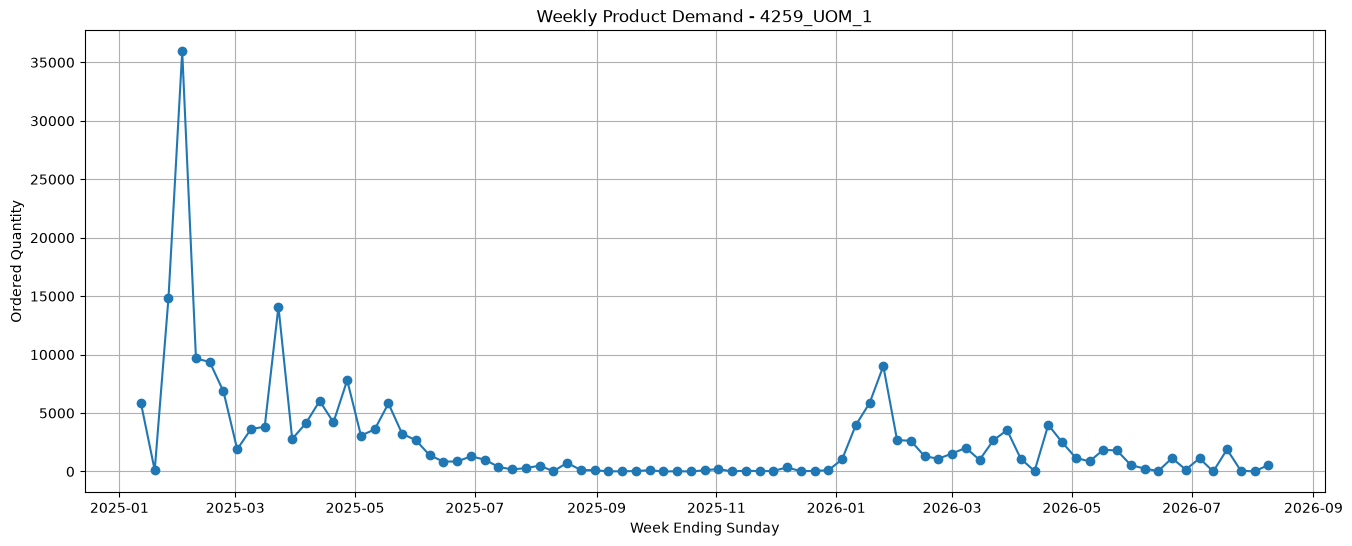

In [13]:
plt.figure(figsize=(16, 6))

plt.plot(
    series.index,
    series.values,
    marker="o"
)

plt.title(
    f"Weekly Product Demand - {TARGET_SKU_KEY}"
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Ordered Quantity")

plt.grid(True)
plt.show()


## 15. Demand summary

In [14]:
print(series.describe())

print()
print(
    "Zero-demand weeks:",
    int((series == 0).sum())
)

print(
    "Zero-demand percentage:",
    round((series == 0).mean() * 100, 2),
    "%"
)

print(
    "Non-zero weeks:",
    int((series > 0).sum())
)


count       83.000000
mean      2600.469880
std       4786.861629
min          0.000000
25%        111.000000
50%       1088.000000
75%       3147.500000
max      35930.000000
Name: weekly_demand_qty, dtype: float64

Zero-demand weeks: 5
Zero-demand percentage: 6.02 %
Non-zero weeks: 78


# Train/Test Split

We use the final **12 complete weeks** as the test period when enough data is available.

This is more robust than hard-coding calendar dates because different products may have different histories.

If the series is too short, the notebook uses about 20% for testing.


## 16. Create the split

In [15]:
if len(series) >= 40:
    test_size = min(12, max(8, len(series) // 5))
else:
    test_size = max(4, len(series) // 5)

train = series.iloc[:-test_size]
test = series.iloc[-test_size:]

print("Training weeks:", len(train))
print("Testing weeks :", len(test))

print()
print("Training:")
print(train.index.min(), "->", train.index.max())

print()
print("Testing:")
print(test.index.min(), "->", test.index.max())


Training weeks: 71
Testing weeks : 12

Training:
2025-01-12 00:00:00 -> 2026-05-17 00:00:00

Testing:
2026-05-24 00:00:00 -> 2026-08-09 00:00:00


## 17. Plot training and testing data

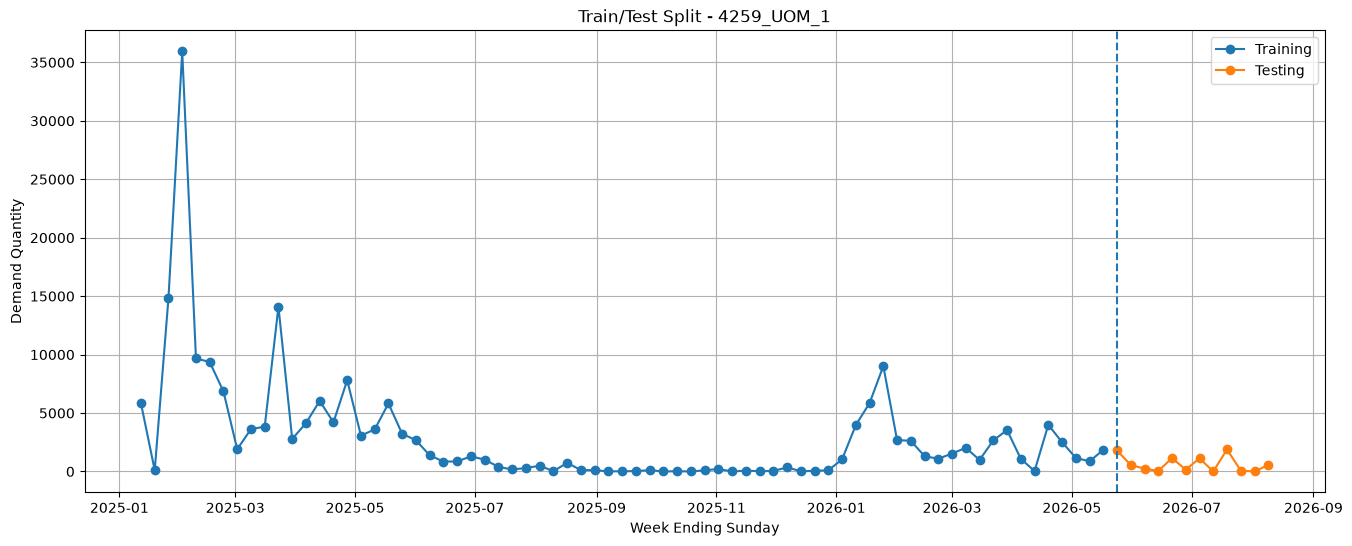

In [16]:
plt.figure(figsize=(16, 6))

plt.plot(
    train.index,
    train.values,
    marker="o",
    label="Training"
)

plt.plot(
    test.index,
    test.values,
    marker="o",
    label="Testing"
)

plt.axvline(
    test.index.min(),
    linestyle="--"
)

plt.title(
    f"Train/Test Split - {TARGET_SKU_KEY}"
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()


# Evaluation Metrics

We use:

- **Mean Absolute Error (MAE)**
- **Root Mean Squared Error (RMSE)**
- **Weighted Absolute Percentage Error (WAPE)**

Lower values are better.


## 18. Metric functions

In [17]:
def wape(actual, predicted):

    actual = np.asarray(
        actual,
        dtype=float
    )

    predicted = np.asarray(
        predicted,
        dtype=float
    )

    denominator = np.sum(
        np.abs(actual)
    )

    if denominator == 0:
        return np.nan

    return (
        np.sum(
            np.abs(
                actual - predicted
            )
        )
        / denominator
    ) * 100


def get_metrics(actual, predicted):

    return {
        "MAE": mean_absolute_error(
            actual,
            predicted
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted
            )
        ),
        "WAPE": wape(
            actual,
            predicted
        )
    }


def evaluate_model(actual, predicted, name):

    metrics = get_metrics(
        actual,
        predicted
    )

    print(name)
    print("-" * 45)

    print(
        f"Mean Absolute Error: "
        f"{metrics['MAE']:,.3f}"
    )

    print(
        f"Root Mean Squared Error: "
        f"{metrics['RMSE']:,.3f}"
    )

    print(
        f"Weighted Absolute Percentage Error: "
        f"{metrics['WAPE']:.2f}%"
    )

    return metrics


# Simple Baselines

Always compare specialized forecasting models against simple rules.


## 19. Last-week naive baseline

In [18]:
last_week_value = train.iloc[-1]

last_week_naive = np.repeat(
    last_week_value,
    len(test)
)

evaluate_model(
    test,
    last_week_naive,
    "Last-Week Naive"   
)


Last-Week Naive
---------------------------------------------
Mean Absolute Error: 1,228.417
Root Mean Squared Error: 1,391.550
Weighted Absolute Percentage Error: 194.09%


{'MAE': 1228.4166666666667,
 'RMSE': np.float64(1391.5504841722416),
 'WAPE': np.float64(194.0882159315339)}

## 20. Four-week mean baseline

In [19]:
four_week_mean_value = train.tail(4).mean()

four_week_mean_predictions = np.repeat(
    four_week_mean_value,
    len(test)
)

evaluate_model(
    test,
    four_week_mean_predictions,
    "Four-Week Mean"
)


Four-Week Mean
---------------------------------------------
Mean Absolute Error: 1,047.750
Root Mean Squared Error: 1,172.503
Weighted Absolute Percentage Error: 165.54%


{'MAE': 1047.75,
 'RMSE': np.float64(1172.502985070827),
 'WAPE': np.float64(165.54312047399605)}

## 21. Four-week median baseline

In [20]:
four_week_median_value = train.tail(4).median()

four_week_median_predictions = np.repeat(
    four_week_median_value,
    len(test)
)

evaluate_model(
    test,
    four_week_median_predictions,
    "Four-Week Median"
)


Four-Week Median
---------------------------------------------
Mean Absolute Error: 988.750
Root Mean Squared Error: 1,100.686
Weighted Absolute Percentage Error: 156.22%


{'MAE': 988.75,
 'RMSE': np.float64(1100.6862632012812),
 'WAPE': np.float64(156.22119815668202)}

# Croston Forecasting

Croston forecasting is designed for intermittent demand.

It separately smooths:

- non-zero demand sizes
- intervals between non-zero demand occurrences

The resulting demand-rate forecast remains constant until new demand information arrives.


## 22. Croston implementation

In [21]:
def croston_fit(series, alpha=0.1, variant="classic"):

    y = np.asarray(
        series,
        dtype=float
    )

    if len(y) == 0:
        raise ValueError(
            "Series must not be empty."
        )

    nonzero_idx = np.flatnonzero(
        y > 0
    )

    if len(nonzero_idx) == 0:

        return {
            "forecast": 0.0,
            "demand_estimate": 0.0,
            "interval_estimate": np.inf,
            "alpha": alpha,
            "variant": variant
        }

    first = nonzero_idx[0]

    z = y[first]
    p = first + 1
    interval = 1

    for t in range(
        first + 1,
        len(y)
    ):

        if y[t] > 0:

            z = (
                alpha * y[t]
                + (1 - alpha) * z
            )

            p = (
                alpha * interval
                + (1 - alpha) * p
            )

            interval = 1

        else:

            interval += 1


    forecast = z / p

    if variant.lower() == "sba":

        forecast = (
            1 - alpha / 2
        ) * forecast


    return {
        "forecast": max(
            float(forecast),
            0.0
        ),
        "demand_estimate": z,
        "interval_estimate": p,
        "alpha": alpha,
        "variant": variant
    }


## 23. Try classic Croston with alpha = 0.1

In [22]:
croston_model = croston_fit(
    train,
    alpha=0.1,
    variant="classic"
)

croston_model


{'forecast': 1849.7062785507385,
 'demand_estimate': np.float64(1880.0501309383044),
 'interval_estimate': np.float64(1.016404686916747),
 'alpha': 0.1,
 'variant': 'classic'}

## 24. Forecast the complete test horizon with Croston

In [23]:
croston_predictions = np.repeat(
    croston_model["forecast"],
    len(test)
)

evaluate_model(
    test,
    croston_predictions,
    "Croston"
)


Croston
---------------------------------------------
Mean Absolute Error: 1,223.172
Root Mean Squared Error: 1,386.022
Weighted Absolute Percentage Error: 193.26%


{'MAE': 1223.171898792282,
 'RMSE': np.float64(1386.0219584520341),
 'WAPE': np.float64(193.25954951293463)}

# Syntetos-Boylan Approximation

The Syntetos-Boylan Approximation applies a bias correction to the classic Croston forecast.


## 25. Fit Syntetos-Boylan Approximation with alpha = 0.1

In [24]:
sba_model = croston_fit(
    train,
    alpha=0.1,
    variant="sba"
)

sba_predictions = np.repeat(
    sba_model["forecast"],
    len(test)
)

evaluate_model(
    test,
    sba_predictions,
    "Syntetos-Boylan Approximation"
)


Syntetos-Boylan Approximation
---------------------------------------------
Mean Absolute Error: 1,152.897
Root Mean Squared Error: 1,305.580
Weighted Absolute Percentage Error: 182.16%


{'MAE': 1152.8973097488013,
 'RMSE': np.float64(1305.5803552925263),
 'WAPE': np.float64(182.15625697150247)}

# Tune the Smoothing Parameter

Instead of assuming `alpha = 0.1`, we can choose alpha using a validation section from the training data.

The tuning does **not** look at the final test set.


## 26. Internal validation split

In [25]:
if len(train) >= 30:
    validation_size = 8
else:
    validation_size = max(
        3,
        len(train) // 5
    )

subtrain = train.iloc[
    :-validation_size
]

validation = train.iloc[
    -validation_size:
]

print(
    "Sub-training weeks:",
    len(subtrain)
)

print(
    "Validation weeks:",
    len(validation)
)


Sub-training weeks: 63
Validation weeks: 8


## 27. Tune alpha for Croston and SBA

In [26]:
alpha_grid = np.arange(
    0.05,
    0.55,
    0.05
)

tuning_rows = []

for alpha in alpha_grid:

    for variant in [
        "classic",
        "sba"
    ]:

        model = croston_fit(
            subtrain,
            alpha=float(alpha),
            variant=variant
        )

        predictions = np.repeat(
            model["forecast"],
            len(validation)
        )

        metrics = get_metrics(
            validation,
            predictions
        )

        tuning_rows.append({
            "variant": variant,
            "alpha": float(alpha),
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"],
            "WAPE": metrics["WAPE"]
        })


tuning_df = pd.DataFrame(
    tuning_rows
).sort_values(
    "WAPE"
)

tuning_df.head(20)


,variant,alpha,MAE,RMSE,WAPE
3,sba,0.10,1092.875000,1286.080268,58.073730
15,sba,0.40,1092.875000,1314.336545,58.073730
11,sba,0.30,1092.875000,1292.829149,58.073730
9,sba,0.25,1092.875000,1285.615627,58.073730
13,sba,0.35,1092.875000,1303.463021,58.073730
17,sba,0.45,1092.875000,1323.640340,58.073730
19,sba,0.50,1092.875000,1331.056000,58.073730
7,sba,0.20,1098.766138,1283.629989,58.386776
5,sba,0.15,1100.821017,1283.641510,58.495969
2,classic,0.10,1103.214693,1283.721292,58.623165


## 28. Select the best tuned Croston-family model

In [27]:
best_tuned = tuning_df.iloc[0]

best_variant = best_tuned["variant"]
best_alpha = float(
    best_tuned["alpha"]
)

print("Best variant:", best_variant)
print("Best alpha  :", best_alpha)
print(
    "Validation WAPE:",
    best_tuned["WAPE"]
)


Best variant: sba
Best alpha  : 0.1
Validation WAPE: 58.07372965792096


## 29. Refit the tuned model on the full training set

In [46]:
tuned_model = croston_fit(
    train,
    alpha=best_alpha,
    variant=best_variant
)

tuned_predictions = np.repeat(
    tuned_model["forecast"],
    len(test)
)

evaluate_model(
    test,
    tuned_predictions,
    f"Tuned {best_variant.upper()}"
)
tuned_predictions


Tuned SBA
---------------------------------------------
Mean Absolute Error: 1,152.897
Root Mean Squared Error: 1,305.580
Weighted Absolute Percentage Error: 182.16%


array([1757.22096462, 1757.22096462, 1757.22096462, 1757.22096462,
       1757.22096462, 1757.22096462, 1757.22096462, 1757.22096462,
       1757.22096462, 1757.22096462, 1757.22096462, 1757.22096462])

In [47]:
# Create a comparison dataframe
comparison_df = pd.DataFrame({
    'week_ending': test.index,
    'actual': test.values,
    'last_week_naive': last_week_naive,
    'four_week_mean': four_week_mean_predictions,
    'four_week_median': four_week_median_predictions,
    'croston': croston_predictions,
    'sba': sba_predictions,
    'tuned_sba': tuned_predictions,
    'walk_forward_sba': walk_forward_predictions.values
})

# Calculate errors for each model
for col in ['last_week_naive', 'four_week_mean', 'four_week_median', 
            'croston', 'sba', 'tuned_sba', 'walk_forward_sba']:
    comparison_df[f'{col}_error'] = comparison_df['actual'] - comparison_df[col]
    comparison_df[f'{col}_abs_error'] = np.abs(comparison_df[f'{col}_error'])
    comparison_df[f'{col}_pct_error'] = (
        comparison_df[f'{col}_error'] / comparison_df['actual'] * 100
    ).replace([np.inf, -np.inf], np.nan)

# Display the comparison
print("="*80)
print("ACTUAL vs FORECASTED COMPARISON - TEST SET")
print("="*80)
print(f"\nProduct: {TARGET_SKU_KEY} ({selected['sku_code']})")
print(f"Test Period: {test.index.min()} to {test.index.max()}")
print("\n")

# Show actual vs predictions side by side
print(comparison_df[[
    'week_ending', 'actual', 'four_week_median', 'tuned_sba', 'walk_forward_sba'
]].to_string(index=False))

print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)

summary_stats = pd.DataFrame({
    'Model': ['Actual'] + list(model_predictions.keys()) + ['Walk-Forward SBA'],
    'Mean': [test.mean()] + [pred.mean() for pred in model_predictions.values()] + [walk_forward_predictions.mean()],
    'Median': [test.median()] + [np.median(pred) for pred in model_predictions.values()] + [walk_forward_predictions.median()],
    'Std Dev': [test.std()] + [np.std(pred) for pred in model_predictions.values()] + [walk_forward_predictions.std()],
    'Min': [test.min()] + [pred.min() for pred in model_predictions.values()] + [walk_forward_predictions.min()],
    'Max': [test.max()] + [pred.max() for pred in model_predictions.values()] + [walk_forward_predictions.max()]
})

print(summary_stats.to_string(index=False))

# Export comparison to CSV
comparison_df.to_csv('test_actual_vs_forecast_comparison.csv', index=False)
print("\n✓ Saved: test_actual_vs_forecast_comparison.csv")

ACTUAL vs FORECASTED COMPARISON - TEST SET

Product: 4259_UOM_1 (JU0093)
Test Period: 2026-05-24 00:00:00 to 2026-08-09 00:00:00


week_ending  actual  four_week_median   tuned_sba  walk_forward_sba
 2026-05-24  1798.0            1511.0 1757.220965       1757.220965
 2026-05-31   552.0            1511.0 1757.220965       1752.380336
 2026-06-07   246.0            1511.0 1757.220965       1631.192620
 2026-06-14    42.0            1511.0 1757.220965       1493.094872
 2026-06-21  1146.0            1511.0 1757.220965       1349.322820
 2026-06-28   159.0            1511.0 1757.220965       1323.510576
 2026-07-05  1128.0            1511.0 1757.220965       1207.277849
 2026-07-12     0.0            1511.0 1757.220965       1193.815693
 2026-07-19  1888.0            1511.0 1757.220965       1193.815693
 2026-07-26    78.0            1511.0 1757.220965       1140.157311
 2026-08-02     0.0            1511.0 1757.220965       1042.920849
 2026-08-09   558.0            1511.0 1757.220965    

# Compare All Models


## 30. Metrics comparison table

In [29]:
model_predictions = {
    "Last-Week Naive":
        last_week_naive,

    "Four-Week Mean":
        four_week_mean_predictions,

    "Four-Week Median":
        four_week_median_predictions,

    "Croston alpha=0.1":
        croston_predictions,

    "SBA alpha=0.1":
        sba_predictions,

    f"Tuned {best_variant.upper()}":
        tuned_predictions
}


metrics_rows = []

for name, predictions in model_predictions.items():

    metrics = get_metrics(
        test,
        predictions
    )

    metrics_rows.append({
        "model": name,
        **metrics
    })


metrics_df = pd.DataFrame(
    metrics_rows
).sort_values(
    "WAPE"
)

metrics_df


,model,MAE,RMSE,WAPE
2,Four-Week Median,988.750000,1100.686263,156.221198
1,Four-Week Mean,1047.750000,1172.502985,165.543120
5,Tuned SBA,1152.897310,1305.580355,182.156257
4,SBA alpha=0.1,1152.897310,1305.580355,182.156257
3,Croston alpha=0.1,1223.171899,1386.021958,193.259550
0,Last-Week Naive,1228.416667,1391.550484,194.088216


## 31. Plot actual versus all forecasts

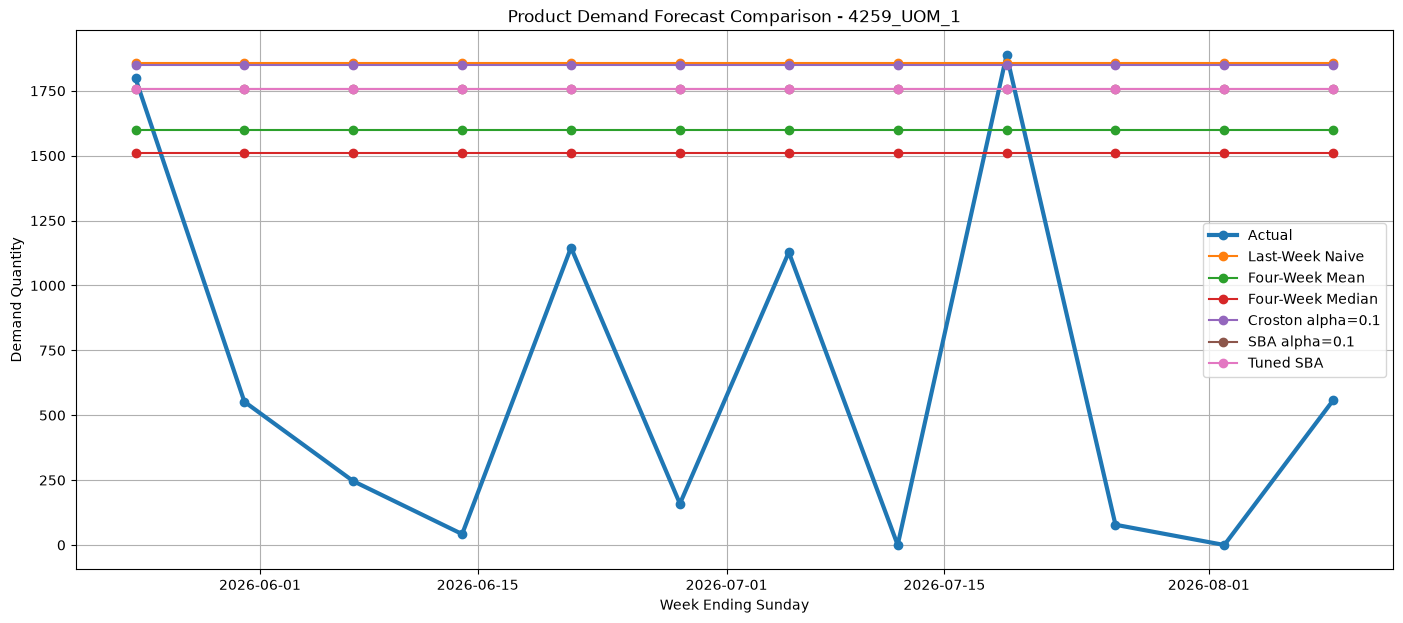

In [30]:
plt.figure(figsize=(17, 7))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

for name, predictions in model_predictions.items():

    plt.plot(
        test.index,
        predictions,
        marker="o",
        label=name
    )


plt.title(
    f"Product Demand Forecast Comparison - "
    f"{TARGET_SKU_KEY}"
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()


# Walk-Forward Croston Validation

The previous Croston test predicted the entire test horizon using only the training data.

Walk-forward testing is closer to real weekly operation:

1. Forecast next week
2. Observe actual demand
3. Add it to history
4. Refit the model
5. Forecast the following week


## 32. Walk-forward Croston-family model

In [31]:
history = list(
    train.values
)

walk_forward_predictions = []

for actual in test.values:

    fitted = croston_fit(
        history,
        alpha=best_alpha,
        variant=best_variant
    )

    prediction = fitted[
        "forecast"
    ]

    walk_forward_predictions.append(
        prediction
    )

    history.append(
        float(actual)
    )


walk_forward_predictions = pd.Series(
    walk_forward_predictions,
    index=test.index
)

evaluate_model(
    test,
    walk_forward_predictions,
    f"Walk-Forward {best_variant.upper()}"
)


Walk-Forward SBA
---------------------------------------------
Mean Absolute Error: 833.546
Root Mean Squared Error: 967.334
Weighted Absolute Percentage Error: 131.70%


{'MAE': 833.5464263620712,
 'RMSE': np.float64(967.3339164080503),
 'WAPE': np.float64(131.69923787155832)}

## 33. Plot walk-forward predictions

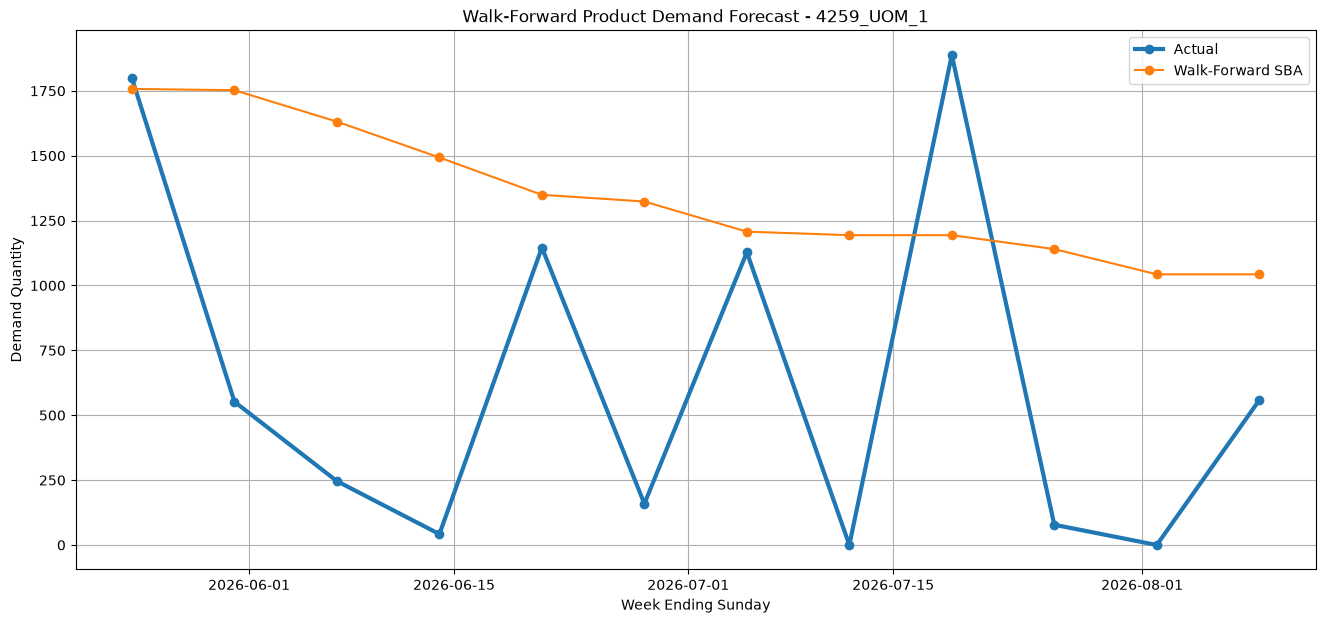

In [32]:
plt.figure(figsize=(16, 7))

plt.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=3,
    label="Actual"
)

plt.plot(
    test.index,
    walk_forward_predictions.values,
    marker="o",
    label=(
        f"Walk-Forward "
        f"{best_variant.upper()}"
    )
)

plt.title(
    f"Walk-Forward Product Demand Forecast - "
    f"{TARGET_SKU_KEY}"
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()


# Train Final Model and Forecast Future Demand

The final model is fitted using **all complete historical weeks** for the selected product.


## 34. Fit final tuned Croston-family model

In [33]:
final_model = croston_fit(
    series,
    alpha=best_alpha,
    variant=best_variant
)

final_model


{'forecast': 911.8249078670211,
 'demand_estimate': np.float64(1139.0324408195686),
 'interval_estimate': np.float64(1.1867199606444605),
 'alpha': 0.1,
 'variant': 'sba'}

## 35. Forecast the next 12 weeks

In [34]:
FORECAST_WEEKS = 12

future_dates = pd.date_range(
    start=series.index.max()
          + pd.Timedelta(weeks=1),

    periods=FORECAST_WEEKS,

    freq="W-SUN"
)

future_predictions = np.repeat(
    final_model["forecast"],
    FORECAST_WEEKS
)

future_df = pd.DataFrame({
    "week_ending":
        future_dates,

    "product_id":
        int(selected["product_id"]),

    "uom_id":
        int(selected["uom_id"]),

    "sku_code":
        selected["sku_code"],

    "forecast_qty":
        future_predictions,

    "model":
        best_variant.upper(),

    "alpha":
        best_alpha
})

future_df


,week_ending,product_id,uom_id,sku_code,forecast_qty,model,alpha
0,2026-08-16,4259,1,JU0093,911.824908,SBA,0.1
1,2026-08-23,4259,1,JU0093,911.824908,SBA,0.1
2,2026-08-30,4259,1,JU0093,911.824908,SBA,0.1
3,2026-09-06,4259,1,JU0093,911.824908,SBA,0.1
4,2026-09-13,4259,1,JU0093,911.824908,SBA,0.1
5,2026-09-20,4259,1,JU0093,911.824908,SBA,0.1
6,2026-09-27,4259,1,JU0093,911.824908,SBA,0.1
7,2026-10-04,4259,1,JU0093,911.824908,SBA,0.1
8,2026-10-11,4259,1,JU0093,911.824908,SBA,0.1
9,2026-10-18,4259,1,JU0093,911.824908,SBA,0.1


## 36. Plot recent history plus future forecast

Croston-family forecasts are often flat until new non-zero demand arrives. That is expected behavior for this model family.


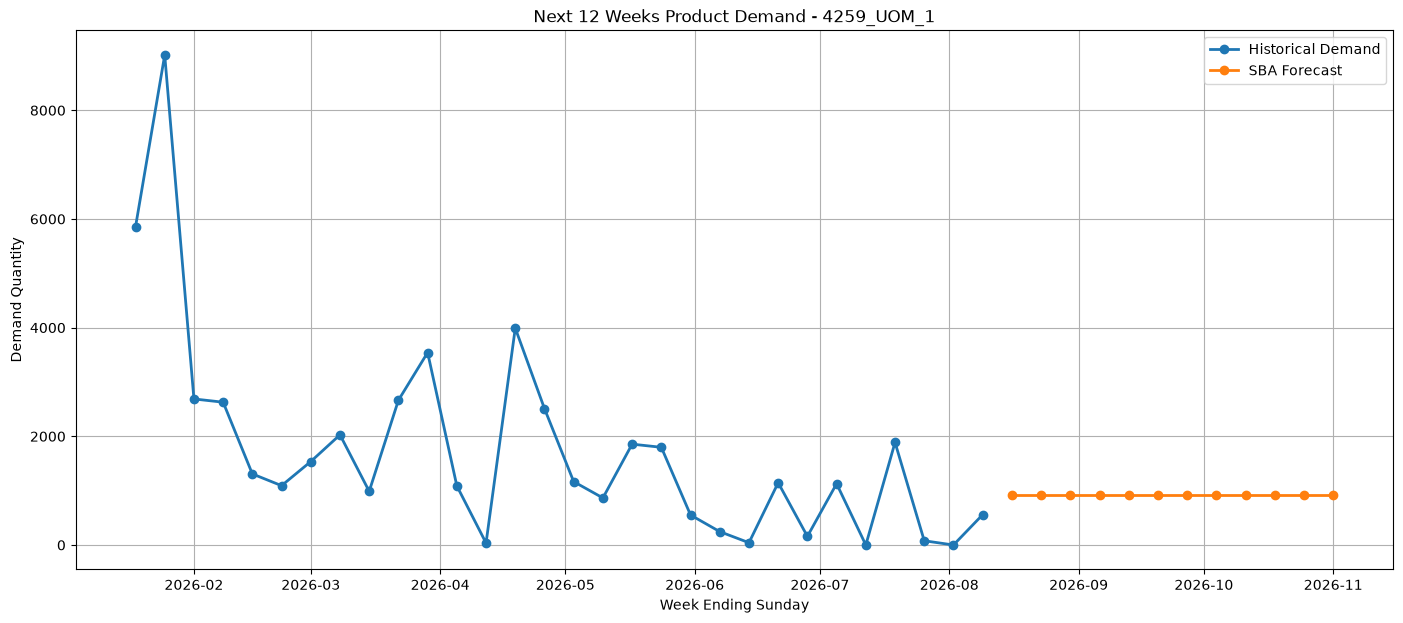

In [35]:
plt.figure(figsize=(17, 7))

recent_history = series.tail(30)

plt.plot(
    recent_history.index,
    recent_history.values,
    marker="o",
    linewidth=2,
    label="Historical Demand"
)

plt.plot(
    future_df["week_ending"],
    future_df["forecast_qty"],
    marker="o",
    linewidth=2,
    label=(
        f"{best_variant.upper()} Forecast"
    )
)

plt.title(
    f"Next {FORECAST_WEEKS} Weeks Product Demand - "
    f"{TARGET_SKU_KEY}"
)

plt.xlabel("Week Ending Sunday")
plt.ylabel("Demand Quantity")

plt.legend()
plt.grid(True)
plt.show()


## 37. Export selected-product forecast

In [36]:
future_df.to_csv(
    "product_demand_12_week_forecast.csv",
    index=False
)

print(
    "Saved: product_demand_12_week_forecast.csv"
)


Saved: product_demand_12_week_forecast.csv


# Batch Evaluation Across Multiple Products

A production forecasting system should not assume one model is best for every product.

This section evaluates several forecasting methods for the highest-demand products and selects the lowest-Weighted-Absolute-Percentage-Error model for each one.


## 38. Helper to backtest one SKU

In [37]:
def backtest_sku(
    series,
    test_size=8,
    alpha=0.1
):

    if len(series) <= test_size + 4:
        return None

    train = series.iloc[:-test_size]
    test = series.iloc[-test_size:]

    predictions = {}

    predictions[
        "Last-Week Naive"
    ] = np.repeat(
        train.iloc[-1],
        len(test)
    )

    predictions[
        "Four-Week Mean"
    ] = np.repeat(
        train.tail(4).mean(),
        len(test)
    )

    predictions[
        "Four-Week Median"
    ] = np.repeat(
        train.tail(4).median(),
        len(test)
    )

    classic = croston_fit(
        train,
        alpha=alpha,
        variant="classic"
    )

    predictions[
        "Croston"
    ] = np.repeat(
        classic["forecast"],
        len(test)
    )

    sba = croston_fit(
        train,
        alpha=alpha,
        variant="sba"
    )

    predictions[
        "SBA"
    ] = np.repeat(
        sba["forecast"],
        len(test)
    )


    rows = []

    for model_name, pred in predictions.items():

        metrics = get_metrics(
            test,
            pred
        )

        rows.append({
            "model":
                model_name,

            "MAE":
                metrics["MAE"],

            "RMSE":
                metrics["RMSE"],

            "WAPE":
                metrics["WAPE"]
        })


    return pd.DataFrame(rows)


## 39. Evaluate the top 20 demand SKUs

In [38]:
TOP_N = min(
    20,
    len(product_profile)
)

batch_rows = []

for _, product_row in product_profile.head(
    TOP_N
).iterrows():

    sku = product_row[
        "sku_key"
    ]

    sku_series = build_weekly_series(
        df,
        sku,
        all_weeks
    )

    result = backtest_sku(
        sku_series,
        test_size=min(
            8,
            max(
                4,
                len(sku_series) // 5
            )
        ),
        alpha=0.1
    )

    if result is None:
        continue

    result["sku_key"] = sku
    result["sku_code"] = product_row[
        "sku_code"
    ]

    result["product_id"] = product_row[
        "product_id"
    ]

    result["uom_id"] = product_row[
        "uom_id"
    ]

    batch_rows.append(
        result
    )


batch_results = pd.concat(
    batch_rows,
    ignore_index=True
)

batch_results.head(20)


,model,MAE,RMSE,WAPE,sku_key,sku_code,product_id,uom_id
0,Last-Week Naive,598.625000,872.546345,96.610853,4259_UOM_1,JU0093,4259,1
1,Four-Week Mean,585.750000,655.191957,94.532984,4259_UOM_1,JU0093,4259,1
2,Four-Week Median,560.375000,690.189738,90.437765,4259_UOM_1,JU0093,4259,1
3,Croston,917.629858,1033.842682,148.094389,4259_UOM_1,JU0093,4259,1
4,SBA,864.367115,979.870089,139.498425,4259_UOM_1,JU0093,4259,1
5,Last-Week Naive,179.250000,275.028180,96.761134,4258_UOM_1,JU0090,4258,1
6,Four-Week Mean,211.875000,228.442416,114.372470,4258_UOM_1,JU0090,4258,1
7,Four-Week Median,218.250000,233.268086,117.813765,4258_UOM_1,JU0090,4258,1
8,Croston,755.464909,785.080993,407.808318,4258_UOM_1,JU0090,4258,1
9,SBA,708.429163,739.930278,382.417902,4258_UOM_1,JU0090,4258,1


## 40. Best model for each product

In [39]:
best_model_per_sku = (
    batch_results
    .sort_values(
        ["sku_key", "WAPE"]
    )
    .groupby(
        "sku_key",
        as_index=False
    )
    .first()
    .sort_values(
        "WAPE"
    )
)

best_model_per_sku[[
    "sku_key",
    "sku_code",
    "product_id",
    "uom_id",
    "model",
    "MAE",
    "RMSE",
    "WAPE"
]]


,sku_key,sku_code,product_id,uom_id,model,MAE,RMSE,WAPE
12,4305_UOM_1,JU0196,4305,1,Four-Week Mean,43.375000,49.941215,68.986083
18,4370_UOM_1,JMP0048,4370,1,Last-Week Naive,33.000000,44.899889,84.615385
8,4259_UOM_1,JU0093,4259,1,Four-Week Median,560.375000,690.189738,90.437765
17,4367_UOM_1,JMP0011,4367,1,Last-Week Naive,93.875000,161.638872,91.251519
15,4320_UOM_1,JMP0067,4320,1,Four-Week Median,107.250000,166.587815,94.701987
14,4317_UOM_1,JMP0068,4317,1,SBA,99.307667,125.180157,95.259153
6,4238_UOM_1,JU0051,4238,1,Last-Week Naive,18.000000,31.855141,96.000000
7,4258_UOM_1,JU0090,4258,1,Last-Week Naive,179.250000,275.028180,96.761134
11,4263_UOM_1,JU0099,4263,1,Last-Week Naive,9.000000,18.973666,100.000000
4,4217_UOM_1,JU0024,4217,1,Last-Week Naive,24.000000,47.717921,100.000000


## 41. Count how often each model wins

In [40]:
best_model_per_sku[
    "model"
].value_counts()


model
Last-Week Naive     16
Four-Week Median     2
Four-Week Mean       1
SBA                  1
Name: count, dtype: int64

## 42. Export product profiles and batch results

In [41]:
product_profile.to_csv(
    "product_demand_profile.csv",
    index=False
)

batch_results.to_csv(
    "product_model_backtest_results.csv",
    index=False
)

best_model_per_sku.to_csv(
    "best_model_per_product.csv",
    index=False
)

print(
    "Saved product_demand_profile.csv"
)

print(
    "Saved product_model_backtest_results.csv"
)

print(
    "Saved best_model_per_product.csv"
)


Saved product_demand_profile.csv
Saved product_model_backtest_results.csv
Saved best_model_per_product.csv


# How to Use the Results

For the selected product, inspect:

```python
metrics_df
```

and compare the Weighted Absolute Percentage Error.

Example:

```text
Model                 WAPE
--------------------  -----
SBA                    34%
Croston                36%
Four-Week Median       52%
Last-Week Naive        71%
```

In that case, Syntetos-Boylan Approximation is the strongest tested model.

However, another product may produce:

```text
Model                 WAPE
--------------------  -----
Four-Week Median       22%
SBA                    35%
Croston                37%
```

Then the simple median baseline is better.

The correct workflow is therefore:

```text
Product
   ↓
Build complete weekly demand series
   ↓
Backtest several models
   ↓
Compare against simple baselines
   ↓
Choose the best model for that SKU
```

Do **not** assume Croston is automatically best for every product.


# Recommended Next Step

After this statistical baseline is working, the next experiment can be a machine-learning demand model using features such as:

- previous week's quantity
- quantity 2, 4, and 8 weeks ago
- rolling averages
- month
- week of year
- holiday/festival indicators
- rainfall or monsoon information
- customer/order frequency

A gradient-boosting model such as Extreme Gradient Boosting (XGBoost) or Light Gradient-Boosting Machine (LightGBM) can then be backtested against these statistical baselines.
